# Brain Tumor MRI – Classification with a CNN and Transfer Learning

**Dataset:** `masoudnickparvar/brain-tumor-mri-dataset` · 4 classes: *glioma, meningioma, notumor, pituitary*

## Contents
| Step | What it does |
|---|---|
| 0 | Configuration, reproducibility, environment versions |
| 1 | Download and data inventory |
| 2 | Exploratory analysis (counts, dimensions, intensity, examples) |
| 3 | **Duplicate / data-leakage check** Training × Testing |
| 4 | Stratified train/validation/test split and `tf.data` pipeline |
| 5 | Metric functions, **95% bootstrap CIs**, calibration, McNemar, Grad-CAM helpers |
| 6 | Models: custom CNN + transfer learning (EfficientNetB0, ResNet50V2, DenseNet121) |
| 7 | Training (feature extraction → fine-tuning) |
| 8 | Evaluation: Accuracy, AUROC, Sensitivity, Specificity, F1, MCC, PPV/NPV, AP, Brier, ECE |
| 9 | Confusion matrices, ROC, PR, calibration, training history, comparison with CIs |
| 10 | Paired statistical tests (exact McNemar + Bonferroni) |
| 11 | Error analysis and **Grad-CAM** |
| 12 | Efficiency (parameters, time) and export (CSV, Excel, figures, weights, predictions) |

> **Model selection:** the "best model" is chosen by **validation MCC**, never on the test set, to avoid selection bias.
> The test set is used only once, for the final report.

## How to run this notebook on your machine

**Requirements**
- Python 3.10–3.12 and Jupyter (JupyterLab or VS Code).
- **TensorFlow ≥ 2.16** (Keras 3). The code uses `.weights.h5` files and Keras 3 layer behaviour.
- Install once (in a terminal, or uncomment the `!pip` line in the next cell):
  `pip install kagglehub "tensorflow>=2.16" scikit-learn scipy matplotlib seaborn pandas pillow tqdm openpyxl`
- Native Windows has no TensorFlow GPU support: use **WSL2**, or run on Google Colab / Kaggle Notebooks (free GPU).

**Data**
- `kagglehub` downloads the dataset once to `~/.cache/kagglehub` (about 150 MB, ~7,000 images: 5,712 in Training and 1,311 in Testing). It is reused on later runs.
- Public datasets normally need no API key. If a login prompt appears, run `kagglehub.login()` or set `KAGGLE_USERNAME` / `KAGGLE_KEY`.

**Pick a profile before running (cell 0, `PROFILE`)**

| | `"cpu"` (default) | `"gpu"` |
|---|---|---|
| Image size | 128 × 128 | 224 × 224 |
| Models | CNN, EfficientNetB0 | CNN, EfficientNetB0, ResNet50V2, DenseNet121 |
| Epochs (CNN / head / fine-tune) | 15 / 5 / 8 | 40 / 10 / 20 |
| RAM used by the image cache | ~0.35 GB | ~1.1 GB |
| Rough run time (estimate) | a few hours on a laptop CPU | ~10–30 min on a modern GPU |

- First run a **smoke test** with `QUICK_RUN = True` (a few minutes) to confirm everything works, then set it back to `False`.
- Epoch 1 is the slowest: images are decoded and resized once, then cached in RAM. Later epochs are faster.
- If you run out of memory, lower `BATCH` (for example 16). If it is too slow, keep `PROFILE = "cpu"` or run only `RUN_MODELS = ["EfficientNetB0"]`.
- Run the cells **top to bottom** (Kernel → Restart & Run All). Section 3 reads every image twice (hashing) and takes a few minutes on CPU.
- Everything is saved to the `outputs/` folder next to the notebook (tables, figures, weights, predictions).
- Results can differ slightly between runs and machines even with a fixed seed (GPU non-determinism), so report your own numbers.

## 0. Configuration

All the knobs are in the block between the dashed lines. Everything else adapts to them.

In [1]:
# !pip install -q kagglehub "tensorflow>=2.16" scikit-learn scipy matplotlib seaborn pandas pillow tqdm openpyxl
import os, sys, random, glob, json, time, hashlib, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve, auc, f1_score,
                             matthews_corrcoef, accuracy_score, classification_report,
                             precision_recall_curve, average_precision_score)
from scipy.stats import binomtest
import kagglehub

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

# ----------------------------- CONFIGURATION -----------------------------
PROFILE = "cpu"                       # "cpu" = light (CPU / simple notebook) | "gpu" = full
SEED = 42
IMG_SIZE = (128, 128) if PROFILE == "cpu" else (224, 224)
FILTERS = [16, 32, 64, 128] if PROFILE == "cpu" else [32, 64, 128, 256]   # CNN width
BATCH = 32                            # lower it (16) if you run out of memory
VAL_SPLIT = 0.15                      # fraction of Training used for validation
QUICK_RUN = False                     # True = smoke test of the whole pipeline (few epochs)
RUN_MODELS = ["CNN", "EfficientNetB0"] if PROFILE == "cpu" else ["CNN", "EfficientNetB0", "ResNet50V2", "DenseNet121"]
EPOCHS = {"cnn": 15, "head": 5, "ft": 8} if PROFILE == "cpu" else {"cnn": 40, "head": 10, "ft": 20}
LR = {"cnn": 1e-3, "head": 1e-3, "ft": 1e-5}
FT_FRACTION = 0.25                    # fraction of the base's final layers to unfreeze
N_BOOT = 1000                         # bootstrap resamples for 95% CIs
HAMMING_THR = 4                       # dHash (64-bit) threshold for near-duplicates
DROP_INTERNAL_DUPLICATES = True       # drop exact duplicates inside Training
REMOVE_TRAIN_TEST_LEAKAGE = True      # drop from Training whatever duplicates Testing
FIG_DPI = 300
OUT = Path("outputs"); FIG_DIR = OUT / "figures"; W_DIR = OUT / "weights"
for d in (OUT, FIG_DIR, W_DIR): d.mkdir(parents=True, exist_ok=True)
if QUICK_RUN:
    EPOCHS = {"cnn": 2, "head": 1, "ft": 1}; N_BOOT = 100
# -------------------------------------------------------------------------

keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
for g in tf.config.list_physical_devices("GPU"):
    try: tf.config.experimental.set_memory_growth(g, True)
    except Exception: pass

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=FIG_DPI, bbox_inches="tight")

env = {"python": sys.version.split()[0], "platform": platform.platform(),
       "tensorflow": tf.__version__, "keras": keras.__version__, "numpy": np.__version__,
       "pandas": pd.__version__, "GPUs": [g.name for g in tf.config.list_physical_devices("GPU")],
       "seed": SEED, "profile": PROFILE}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
print(json.dumps(env, indent=2))

{
  "python": "3.14.6",
  "platform": "Windows-10-10.0.19045-SP0",
  "tensorflow": "2.22.0-rc0",
  "keras": "3.15.1",
  "numpy": "2.4.6",
  "pandas": "2.3.3",
  "GPUs": [],
  "seed": 42,
  "profile": "cpu"
}


## 1. Download and data inventory

Builds one table (`df`) with the path, class and original split (Training/Testing) of every image. Check that the class counts match what you expect.

In [2]:
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)

def find_dir(root, name):
    for dp, dn, _ in os.walk(root):
        if name in dn:
            return os.path.join(dp, name)
    raise FileNotFoundError(name)

TRAIN_DIR, TEST_DIR = find_dir(path, "Training"), find_dir(path, "Testing")

def list_images(root, split):
    rows = []
    for c in sorted(os.listdir(root)):
        cdir = os.path.join(root, c)
        if not os.path.isdir(cdir): continue
        for f in os.listdir(cdir):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                rows.append((os.path.join(cdir, f), c, split))
    return pd.DataFrame(rows, columns=["path", "class", "split"])

df = pd.concat([list_images(TRAIN_DIR, "Training"), list_images(TEST_DIR, "Testing")],
               ignore_index=True)
class_names = sorted(df["class"].unique())
K = len(class_names)
class_to_idx = {c: i for i, c in enumerate(class_names)}
df["label"] = df["class"].map(class_to_idx)
print("Classes:", class_names)
display(pd.crosstab(df["class"], df["split"], margins=True))

Path to dataset files: C:\Users\sanch\.cache\kagglehub\datasets\masoudnickparvar\brain-tumor-mri-dataset\versions\2
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


split,Testing,Training,All
class,,,
glioma,400,1400,1800
meningioma,400,1400,1800
notumor,400,1400,1800
pituitary,400,1400,1800
All,1600,5600,7200


## 2. Exploratory analysis

Class balance, original image sizes, colour mode and brightness, plus example images. Strong differences in brightness or size between classes would be a warning sign of dataset bias.

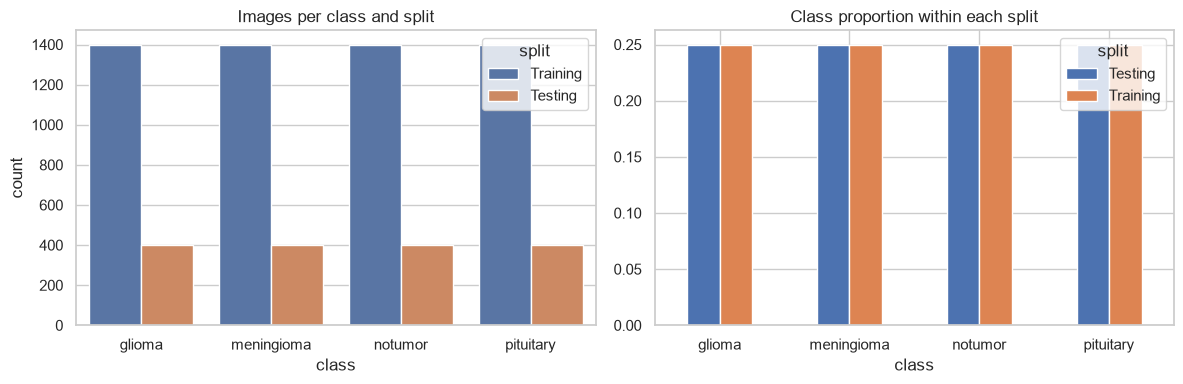

  0%|          | 0/600 [00:00<?, ?it/s]

Colour modes: {'RGB': 343, 'L': 257}
Distinct image sizes in the sample: 96


class         glioma  meningioma  notumor  pituitary
width  count   149.0       160.0    155.0      136.0
       mean    505.7       486.9    306.2      500.3
       std      42.1        80.3    158.8       75.8
       min     200.0       200.0    150.0      256.0
       25%     512.0       512.0    218.0      512.0
       50%     512.0       512.0    228.0      512.0
       75%     512.0       512.0    361.5      512.0
       max     564.0       554.0   1024.0      892.0
height count   149.0       160.0    155.0      136.0
       mean    507.3       488.8    317.0      499.5
       std      40.5        74.1    160.8       72.9
       min     234.0       214.0    168.0      256.0
       25%     512.0       512.0    223.0      512.0
       50%     512.0       512.0    236.0      512.0
       75%     512.0       512.0    400.0      512.0
       max     665.0       554.0   1024.0      826.0
mean   count   149.0       160.0    155.0      136.0
       mean     35.5        42.2     63.6       49.1
       std      14.7        13.1     21.9        8.7
       min      17.8        22.1     21.9       26.6
       25%      25.9        34.4     48.1       43.2
       50%      31.7        39.5     62.8       49.1
       75%      40.6        45.7     76.9       54.9
       max     122.3       116.5    122.9       74.5
std    count   149.0       160.0    155.0      136.0
       mean     39.1        46.0     62.1       41.0
       std       8.7         7.7     15.4        4.9
       min      20.8        28.7     30.1       23.0
       25%      34.7        41.5     51.0       37.8
       50%      38.4        45.0     60.2       41.2
       75%      42.4        48.8     75.8       44.0
       max      88.4        81.8     97.7       59.6

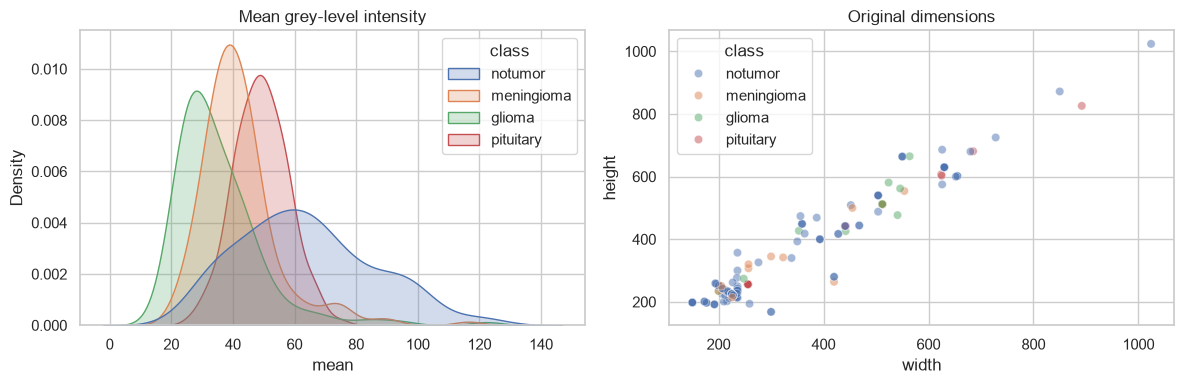

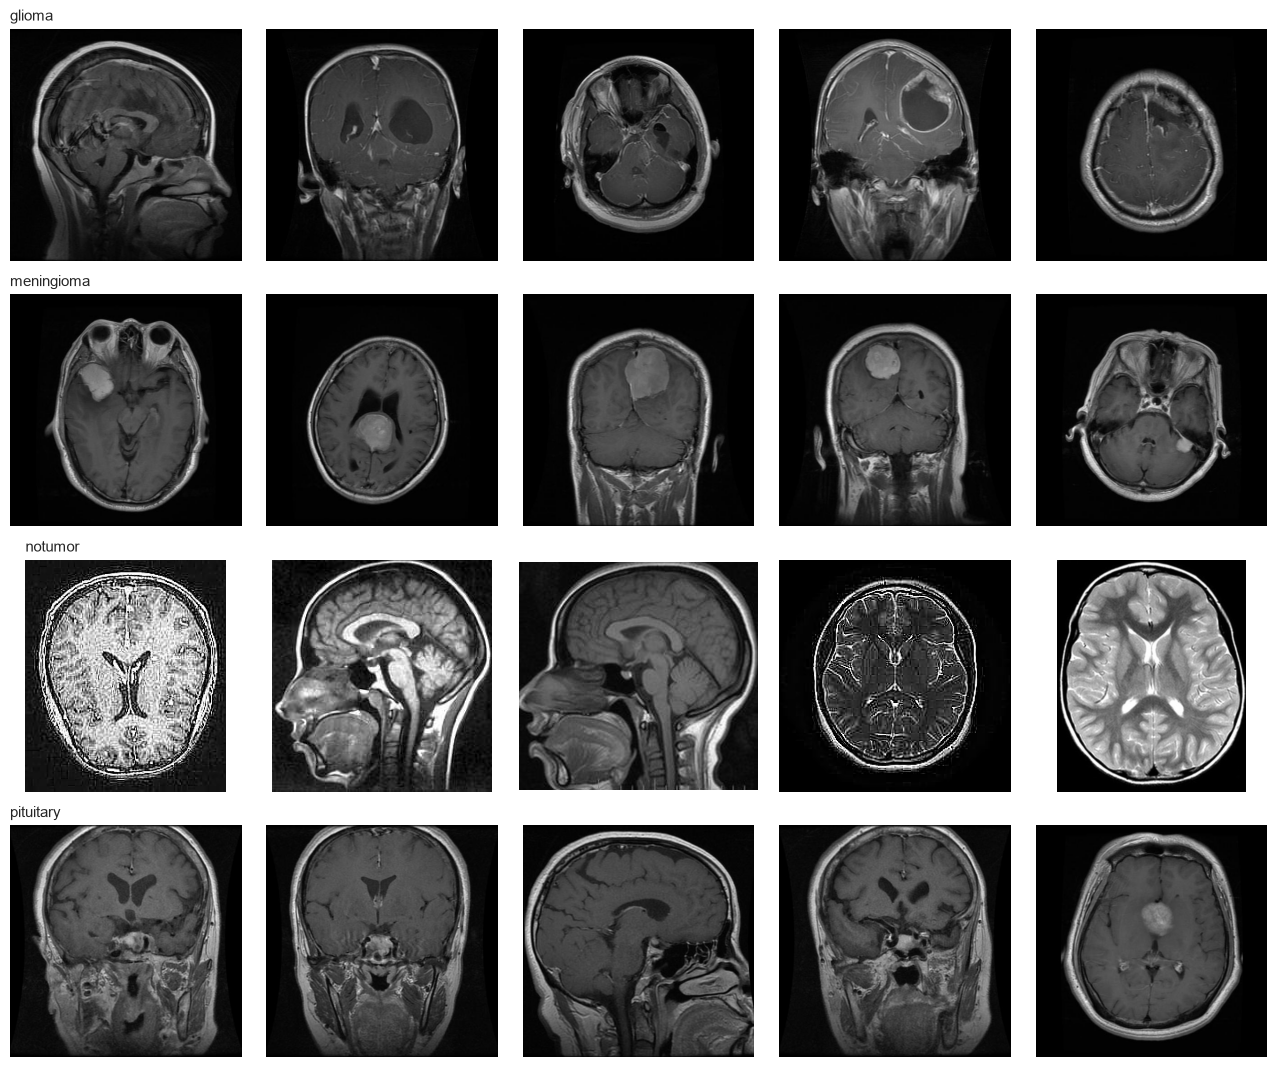

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="class", hue="split", ax=ax[0]); ax[0].set_title("Images per class and split")
(df.groupby("split")["class"].value_counts(normalize=True).unstack(0)
   .plot(kind="bar", ax=ax[1], rot=0)); ax[1].set_title("Class proportion within each split")
plt.tight_layout(); savefig("eda_counts"); plt.show()

# Dimensions, colour mode and mean intensity (random sample)
sample = df.sample(min(600, len(df)), random_state=SEED)
meta = []
for p, c in tqdm(zip(sample.path, sample["class"]), total=len(sample)):
    with Image.open(p) as im:
        w, h = im.size; mode = im.mode
        g = np.asarray(im.convert("L"), dtype=np.float32)
    meta.append((c, w, h, mode, g.mean(), g.std()))
meta = pd.DataFrame(meta, columns=["class", "width", "height", "mode", "mean", "std"])
print("Colour modes:", meta["mode"].value_counts().to_dict())
print("Distinct image sizes in the sample:", meta[["width", "height"]].drop_duplicates().shape[0])
display(meta.groupby("class")[["width", "height", "mean", "std"]].describe().T.round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=meta, x="mean", hue="class", fill=True, alpha=.25, ax=ax[0]); ax[0].set_title("Mean grey-level intensity")
sns.scatterplot(data=meta, x="width", y="height", hue="class", alpha=.5, ax=ax[1]); ax[1].set_title("Original dimensions")
plt.tight_layout(); savefig("eda_intensity_dimensions"); plt.show()

# Examples per class
fig, axes = plt.subplots(K, 5, figsize=(13, 2.7 * K))
for i, c in enumerate(class_names):
    paths = df[(df["class"] == c) & (df.split == "Training")].sample(5, random_state=SEED).path
    for j, p in enumerate(paths):
        axes[i, j].imshow(Image.open(p).convert("RGB")); axes[i, j].axis("off")
        if j == 0: axes[i, j].set_title(c, loc="left", fontsize=11)
plt.tight_layout(); savefig("eda_examples"); plt.show()

## 3. Duplicates and data leakage (Training × Testing)

This dataset aggregates public sources and can contain **identical or near-identical images** across splits, which inflates the metrics.
We compute **MD5** (exact duplicates) and a **64-bit dHash** (near-duplicates, Hamming distance ≤ `HAMMING_THR`).
Run the notebook with `REMOVE_TRAIN_TEST_LEAKAGE = True` and `False` and report both as a sensitivity analysis.
Note: the dataset has no patient ID, so slices from the same patient may still sit in different splits; this cannot be checked here and should be listed as a limitation.

In [4]:
def md5_file(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def dhash(p, size=8):
    with Image.open(p) as im:
        im = im.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(im, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())     # 8 bytes

df["md5"] = [md5_file(p) for p in tqdm(df.path, desc="MD5")]
H = np.stack([dhash(p) for p in tqdm(df.path, desc="dHash")])      # (N, 8) uint8
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

is_tr = (df.split == "Training").values
is_te = (df.split == "Testing").values
Htr, Hte = H[is_tr], H[is_te]

min_dist = np.full(len(Htr), 64, dtype=np.int32)       # smallest distance from each training image to any test image
for i in range(len(Hte)):
    min_dist = np.minimum(min_dist, POP[Htr ^ Hte[i]].sum(1))

tr_idx = df.index[is_tr]
exact_leak = df.loc[tr_idx, "md5"].isin(set(df.loc[is_te, "md5"])).values
near_leak = min_dist <= HAMMING_THR
dup_internal = df.loc[tr_idx, "md5"].duplicated(keep="first").values

report = pd.Series({
    "Training (n)": int(is_tr.sum()), "Testing (n)": int(is_te.sum()),
    "Exact duplicates inside Training": int(dup_internal.sum()),
    "Training image identical to a Testing image (MD5)": int(exact_leak.sum()),
    f"Training image near-identical to Testing (dHash <= {HAMMING_THR})": int(near_leak.sum()),
})
display(report.to_frame("count"))

flag = pd.DataFrame(False, index=df.index, columns=["dup_internal", "leak"])
flag.loc[tr_idx, "dup_internal"] = dup_internal
flag.loc[tr_idx, "leak"] = exact_leak | near_leak

drop = pd.Series(False, index=df.index)
if DROP_INTERNAL_DUPLICATES:    drop |= flag["dup_internal"]
if REMOVE_TRAIN_TEST_LEAKAGE:   drop |= flag["leak"]
df_clean = df[~drop].reset_index(drop=True)
print(f"\nRemoved {int(drop.sum())} Training images. {len(df_clean)} images remain.")
display(pd.crosstab(df_clean["class"], df_clean["split"], margins=True))
df.to_csv(OUT / "image_inventory.csv", index=False)

MD5:   0%|          | 0/7200 [00:00<?, ?it/s]

dHash:   0%|          | 0/7200 [00:00<?, ?it/s]

,count
Training (n),5600
Testing (n),1600
Exact duplicates inside Training,171
Training image identical to a Testing image (MD5),0
Training image near-identical to Testing (dHash <= 4),1623



Removed 1733 Training images. 5467 images remain.


split,Testing,Training,All
class,,,
glioma,400,1157,1557
meningioma,400,1140,1540
notumor,400,460,860
pituitary,400,1110,1510
All,1600,3867,5467


## 4. Stratified split and `tf.data` pipeline

Validation is carved out of Training (stratified by class). Images are decoded and resized **once**, stored in RAM as `uint8` (cache), and converted to `float32` per batch. `shuffle=False` for validation/test keeps predictions aligned with labels.

In [5]:
trainval = df_clean[df_clean.split == "Training"]
train_df, val_df = train_test_split(trainval, test_size=VAL_SPLIT,
                                    stratify=trainval["label"], random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
test_df = df_clean[df_clean.split == "Testing"].reset_index(drop=True)

display(pd.DataFrame({"train": train_df["class"].value_counts(),
                      "validation": val_df["class"].value_counts(),
                      "test": test_df["class"].value_counts()}).fillna(0).astype(int))

def decode(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(tf.round(img), tf.uint8)          # uint8: the RAM cache is 4x smaller
    img.set_shape(IMG_SIZE + (3,))
    return img, label

def make_ds(d, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values.astype("int32")))
    ds = ds.map(decode, num_parallel_calls=AUTOTUNE).cache()      # decode/resize only once (1st epoch)
    if shuffle:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

counts = np.bincount(train_df["label"], minlength=K)
class_weight = {i: len(train_df) / (K * c) for i, c in enumerate(counts)}
print("class_weight:", {class_names[i]: round(w, 3) for i, w in class_weight.items()})

,train,validation,test
class,,,
glioma,983,174,400
meningioma,969,171,400
notumor,391,69,400
pituitary,943,167,400


class_weight: {'glioma': np.float64(0.836), 'meningioma': np.float64(0.848), 'notumor': np.float64(2.101), 'pituitary': np.float64(0.871)}


## 5. Metric functions, bootstrap CIs, calibration, tests and plots

Definitions used (all multiclass metrics are computed **one-vs-rest** per class, then macro-averaged):
- **Sensitivity** = TP / (TP + FN) · **Specificity** = TN / (TN + FP) · **PPV** (precision) = TP / (TP + FP) · **NPV** = TN / (TN + FN)
- **AUROC**: macro one-vs-rest · **MCC**: multiclass (Gorodkin) for the global value, binary MCC for each class
- **ECE / Brier**: calibration quality of the predicted probabilities (lower is better)
- 95% CIs: **Wilson** for per-class sensitivity/specificity, **bootstrap** (percentiles) for global metrics

In [6]:
def confusion_stats(cm):
    TP = np.diag(cm).astype(float); FN = cm.sum(1) - TP; FP = cm.sum(0) - TP
    TN = cm.sum() - (TP + FN + FP)
    return TP, FP, FN, TN

def safe_div(a, b):
    return np.where(b > 0, a / np.where(b == 0, 1, b), np.nan)

def global_metrics(y_true, y_pred, y_prob, K):
    cm = confusion_matrix(y_true, y_pred, labels=range(K))
    TP, FP, FN, TN = confusion_stats(cm)
    sens, spec = safe_div(TP, TP + FN), safe_div(TN, TN + FP)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "auroc_macro": roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro", labels=list(range(K))),
        "sens_macro": np.nanmean(sens),
        "spec_macro": np.nanmean(spec),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }

def bootstrap_ci(y_true, y_pred, y_prob, K, n=1000, seed=42):
    rng = np.random.default_rng(seed); N = len(y_true); recs = []
    for _ in range(n):
        idx = rng.integers(0, N, N)
        try: recs.append(global_metrics(y_true[idx], y_pred[idx], y_prob[idx], K))
        except ValueError: continue
    b = pd.DataFrame(recs)
    return b.quantile(.025), b.quantile(.975)

def wilson(k, n, z=1.96):
    if n == 0: return np.nan, np.nan
    p = k / n; den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return c - h, c + h

def per_class_table(y_true, y_pred, y_prob, class_names):
    K = len(class_names)
    cm = confusion_matrix(y_true, y_pred, labels=range(K))
    TP, FP, FN, TN = confusion_stats(cm)
    y_bin = label_binarize(y_true, classes=range(K))
    rows = []
    for i, c in enumerate(class_names):
        sens = TP[i] / (TP[i] + FN[i]); spec = TN[i] / (TN[i] + FP[i])
        ppv = TP[i] / (TP[i] + FP[i]) if (TP[i] + FP[i]) else np.nan
        npv = TN[i] / (TN[i] + FN[i]) if (TN[i] + FN[i]) else np.nan
        f1 = 2 * ppv * sens / (ppv + sens) if (ppv + sens) else np.nan
        s_lo, s_hi = wilson(TP[i], TP[i] + FN[i]); e_lo, e_hi = wilson(TN[i], TN[i] + FP[i])
        rows.append({"class": c, "n": int(TP[i] + FN[i]),
                     "sensitivity": sens, "sens_CI95": f"[{s_lo:.3f}, {s_hi:.3f}]",
                     "specificity": spec, "spec_CI95": f"[{e_lo:.3f}, {e_hi:.3f}]",
                     "PPV(precision)": ppv, "NPV": npv, "F1": f1,
                     "AUROC": roc_auc_score(y_bin[:, i], y_prob[:, i]),
                     "AP": average_precision_score(y_bin[:, i], y_prob[:, i]),
                     "MCC_ovr": matthews_corrcoef(y_bin[:, i], (y_pred == i).astype(int)),
                     "TP": int(TP[i]), "FP": int(FP[i]), "FN": int(FN[i]), "TN": int(TN[i])})
    return pd.DataFrame(rows).set_index("class")

def expected_calibration_error(y_true, y_prob, n_bins=15):
    conf = y_prob.max(1); acc = (y_prob.argmax(1) == y_true).astype(float)
    edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): ece += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return ece

def brier_multiclass(y_true, y_prob):
    onehot = np.eye(y_prob.shape[1])[y_true]
    return float(np.mean(np.sum((y_prob - onehot) ** 2, axis=1)))

def mcnemar_exact(y_true, pred_a, pred_b):
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    b = int(np.sum(a_ok & ~b_ok)); c = int(np.sum(~a_ok & b_ok)); n = b + c
    p = 1.0 if n == 0 else binomtest(min(b, c), n, 0.5).pvalue
    return p, b, c

def macro_roc(y_true, y_prob, K):
    y_bin = label_binarize(y_true, classes=range(K)); grid = np.linspace(0, 1, 501); tprs = []
    for i in range(K):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i]); tprs.append(np.interp(grid, fpr, tpr))
    m = np.mean(tprs, 0); m[0] = 0.0
    return grid, m

# ------------------------------ plots ------------------------------
def plot_confusion_matrices(cm, class_names, title, fname):
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0])
    ax[0].set_title(f"{title}\nConfusion matrix (counts)")
    sns.heatmap(cmn, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1,
                xticklabels=class_names, yticklabels=class_names, ax=ax[1])
    ax[1].set_title(f"{title}\nRow-normalised (diagonal = sensitivity)")
    for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True")
    plt.tight_layout(); savefig(fname); plt.show()

def plot_roc_pr(y_true, y_prob, class_names, title, fname):
    K = len(class_names); y_bin = label_binarize(y_true, classes=range(K))
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    for i, c in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
        ax[0].plot(fpr, tpr, label=f"{c} (AUC={auc(fpr, tpr):.3f})")
        pr, rc, _ = precision_recall_curve(y_bin[:, i], y_prob[:, i])
        ax[1].plot(rc, pr, label=f"{c} (AP={average_precision_score(y_bin[:, i], y_prob[:, i]):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", alpha=.4)
    ax[0].set(xlabel="1 - Specificity", ylabel="Sensitivity", title=f"{title} – ROC (OvR)")
    ax[1].set(xlabel="Sensitivity (recall)", ylabel="Precision", title=f"{title} – Precision-Recall")
    ax[0].legend(loc="lower right"); ax[1].legend(loc="lower left")
    plt.tight_layout(); savefig(fname); plt.show()

def plot_history(hists, title, fname):
    h = {}
    for hh in hists:
        for k, v in hh.history.items(): h.setdefault(k, []).extend(v)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m, t in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        a.plot(h[m], label="train"); a.plot(h["val_" + m], label="validation")
        if len(hists) == 2: a.axvline(len(hists[0].history["loss"]) - .5, color="gray", ls="--", label="fine-tuning starts")
        a.set(title=f"{title} – {t}", xlabel="Epoch"); a.legend()
    plt.tight_layout(); savefig(fname); plt.show()

## 6. Models

- **CNN:** 4 blocks of (Conv-BN-ReLU ×2, MaxPool, Dropout), global average pooling and a small dense head, trained from scratch.
- **Transfer learning:** ImageNet-pretrained base (frozen), global average pooling, dropout and a softmax layer. Each base gets the pre-processing it expects (inputs are always 0–255).
- Data augmentation (flip, small rotation/zoom/contrast) is active only during training.

In [7]:
data_aug = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")          # active only in training (inactive at inference)

def build_cnn(num_classes=K):
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = data_aug(inp)
    x = layers.Rescaling(1. / 255)(x)
    for i, f in enumerate(FILTERS):
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu")(x)
        x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.Activation("relu", name=f"blk{i}_act2")(x)
        x = layers.MaxPooling2D()(x); x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x); x = layers.Dropout(0.5)(x)
    return keras.Model(inp, layers.Dense(num_classes, activation="softmax")(x), name="CNN")

# Pre-processing required by each base network (input is always 0-255)
TL_CONFIG = {
    "EfficientNetB0": dict(ctor=keras.applications.EfficientNetB0, prep=None),   # built in
    "ResNet50V2":     dict(ctor=keras.applications.ResNet50V2,
                           prep=lambda: layers.Rescaling(1 / 127.5, offset=-1, name="prep")),
    "DenseNet121":    dict(ctor=keras.applications.DenseNet121,
                           prep=lambda: layers.Normalization(mean=[123.675, 116.28, 103.53],
                                         variance=[58.395**2, 57.12**2, 57.375**2], name="prep")),
}

def build_tl(arch, num_classes=K):
    cfg = TL_CONFIG[arch]
    base = cfg["ctor"](include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    base.trainable = False
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = data_aug(inp)
    if cfg["prep"] is not None: x = cfg["prep"]()(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="drop")(x)
    out = layers.Dense(num_classes, activation="softmax", name="out")(x)
    return keras.Model(inp, out, name=arch), base

def unfreeze_top(base, frac):
    base.trainable = True
    n = int(len(base.layers) * frac)
    for l in base.layers[:-n]: l.trainable = False
    for l in base.layers:                         # BatchNorm stays frozen during fine-tuning
        if isinstance(l, layers.BatchNormalization): l.trainable = False

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def callbacks():
    return [keras.callbacks.EarlyStopping("val_loss", patience=6, restore_best_weights=True, verbose=1),
            keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1)]

build_cnn().summary()

Model: "CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ augmentation (Sequential)            │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 128, 128, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 128, 128, 16)        │             432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128, 128, 16)        │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 128, 128, 16)        │           2,304 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128, 128, 16)        │              64 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ blk0_act2 (Activation)               │ (None, 128, 128, 16)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64, 64, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 64, 64, 32)          │           4,608 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 64, 64, 32)          │           9,216 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 64, 64, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ blk1_act2 (Activation)               │ (None, 64, 64, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32, 32, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 311,988 (1.19 MB)

 Trainable params: 311,028 (1.19 MB)

 Non-trainable params: 960 (3.75 KB)

## 7. Training

Transfer-learning models train in two phases: (1) only the new head with the base frozen, (2) fine-tuning of the top layers of the base with a much smaller learning rate. EarlyStopping restores the best validation weights, so the epoch counts are upper limits. Progress bars show `step/total – time per step`.


==================== CNN ====================
Epoch 1/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 117s 1s/step - accuracy: 0.5876 - loss: 0.9510 - val_accuracy: 0.2995 - val_loss: 2.6293 - learning_rate: 0.0010
Epoch 2/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.6652 - loss: 0.7851 - val_accuracy: 0.5164 - val_loss: 1.3501 - learning_rate: 0.0010
Epoch 3/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.7358 - loss: 0.6698 - val_accuracy: 0.4561 - val_loss: 1.3877 - learning_rate: 0.0010
Epoch 4/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.7444 - loss: 0.6166 - val_accuracy: 0.4699 - val_loss: 1.3332 - learning_rate: 0.0010
Epoch 5/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 111s 1s/step - accuracy: 0.7931 - loss: 0.5286 - val_accuracy: 0.4355 - val_loss: 1.6599 - learning_rate: 0.0010
Epoch 6/15
103/103 ━━━━━━━━━━━━━━━━━━━━ 130s 965ms/step - accuracy: 0.8028 - loss: 0.4928 - val_accuracy: 0.6644 - val_loss: 0.9617 - learning_rate: 0.0010
Epoch 7/15
103/103 ━━━━━━━━━━━━━

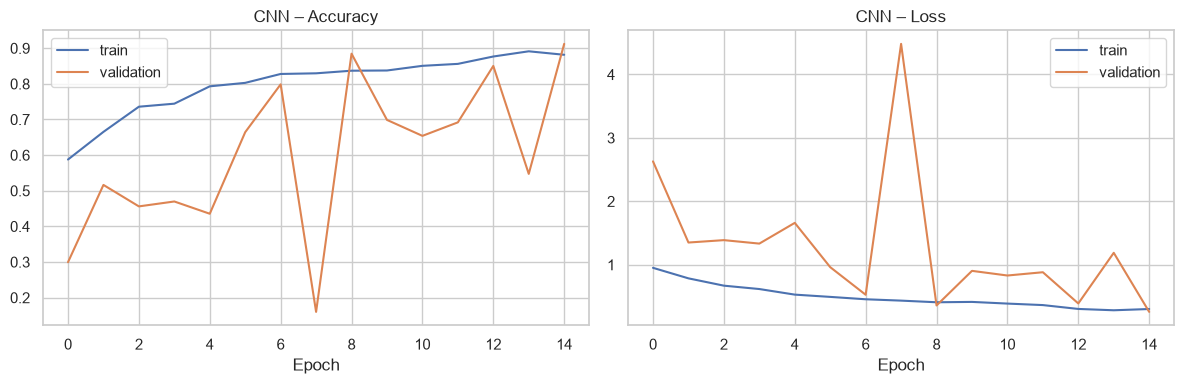


==================== EfficientNetB0 ====================
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 30s 2us/step
Epoch 1/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 65s 497ms/step - accuracy: 0.6038 - loss: 0.9190 - val_accuracy: 0.7091 - val_loss: 0.7352 - learning_rate: 0.0010
Epoch 2/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 41s 400ms/step - accuracy: 0.7547 - loss: 0.6169 - val_accuracy: 0.7487 - val_loss: 0.6353 - learning_rate: 0.0010
Epoch 3/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 43s 418ms/step - accuracy: 0.7888 - loss: 0.5392 - val_accuracy: 0.7590 - val_loss: 0.6070 - learning_rate: 0.0010
Epoch 4/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 41s 394ms/step - accuracy: 0.8107 - loss: 0.5077 - val_accuracy: 0.7332 - val_loss: 0.6592 - learning_rate: 0.0010
Epoch 5/5
103/103 ━━━━━━━━━━━━━━━━━━━━ 43s 415ms/step - accuracy: 0.8147 - loss: 0.4857 - val_accuracy: 0.8055 - val_loss: 0.5266 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.
Epoch 1/8
103/103 ━━━━━━━━━━━━━━━━━━━━ 105s 794ms/step - accu

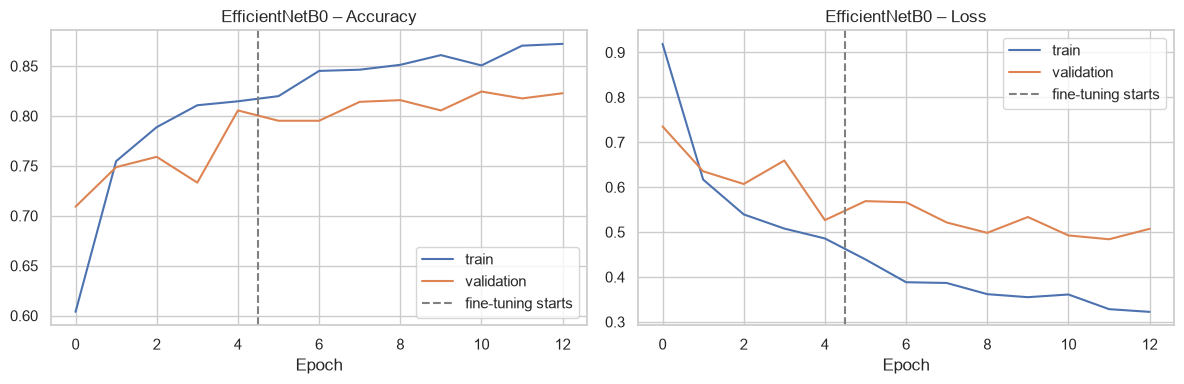

In [8]:
registry = {}      # name -> dict(model, base, hist, train_time_s)

for name in RUN_MODELS:
    print(f"\n{'=' * 20} {name} {'=' * 20}")
    t0 = time.perf_counter()
    if name == "CNN":
        model, base = build_cnn(), None
        compile_model(model, LR["cnn"])
        hists = [model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS["cnn"],
                           class_weight=class_weight, callbacks=callbacks())]
    else:
        model, base = build_tl(name)
        compile_model(model, LR["head"])                                   # phase 1: head only
        h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS["head"],
                       class_weight=class_weight, callbacks=callbacks())
        unfreeze_top(base, FT_FRACTION); compile_model(model, LR["ft"])    # phase 2: fine-tuning
        h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS["ft"],
                       class_weight=class_weight, callbacks=callbacks())
        hists = [h1, h2]
    elapsed = time.perf_counter() - t0
    model.save_weights(W_DIR / f"{name}.weights.h5")
    registry[name] = dict(model=model, base=base, hist=hists, train_time_s=elapsed)
    plot_history(hists, name, f"history_{name}")

## 8. Evaluation (validation to select, test to report)

Predictions are made on the untouched test set. The global table shows each metric as `value [95% bootstrap CI]`; the per-class tables show sensitivity/specificity with Wilson CIs plus PPV, NPV, F1, AUROC, AP, MCC and the raw TP/FP/FN/TN counts.

In [9]:
def predict_df(model, d):
    prob = model.predict(make_ds(d), verbose=0)     # order preserved (no shuffle)
    return d["label"].values, prob.argmax(1), prob

rows_global, rows_ci, per_class, cms = [], [], {}, {}
for name, r in registry.items():
    yv, pv, probv = predict_df(r["model"], val_df)
    t0 = time.perf_counter(); yt, pt, probt = predict_df(r["model"], test_df)
    r["ms_per_image"] = (time.perf_counter() - t0) / len(test_df) * 1000
    r["val"], r["test"] = (yv, pv, probv), (yt, pt, probt)
    r["val_mcc"] = matthews_corrcoef(yv, pv)

    gm = global_metrics(yt, pt, probt, K)
    lo, hi = bootstrap_ci(yt, pt, probt, K, n=N_BOOT, seed=SEED)
    gm.update(f1_weighted=f1_score(yt, pt, average="weighted"),
              brier=brier_multiclass(yt, probt), ece=expected_calibration_error(yt, probt))
    rows_global.append({"model": name, **gm})
    rows_ci.append({"model": name, **{k: f"{gm[k]:.4f} [{lo[k]:.4f}-{hi[k]:.4f}]" for k in lo.index}})
    r["gm"], r["ci"] = gm, (lo, hi)
    per_class[name] = per_class_table(yt, pt, probt, class_names)
    cms[name] = confusion_matrix(yt, pt, labels=range(K))

    print(f"\n===== {name} (test) =====")
    display(per_class[name].round(4))
    print(classification_report(yt, pt, target_names=class_names, digits=4))

summary = pd.DataFrame(rows_global).set_index("model")
summary_ci = pd.DataFrame(rows_ci).set_index("model")
best = max(registry, key=lambda n: registry[n]["val_mcc"])
print("\n>>> Best model by validation MCC:", best)
print("\nGlobal metrics on the TEST set (value [95% bootstrap CI]):")
display(summary_ci)
print("\nGlobal metrics (point estimates, incl. weighted F1, Brier and ECE):")
display(summary.round(4))


===== CNN (test) =====


,n,sensitivity,sens_CI95,specificity,spec_CI95,PPV(precision),NPV,F1,AUROC,AP,MCC_ovr,TP,FP,FN,TN
class,,,,,,,,,,,,,,,
glioma,400,0.5350,"[0.486, 0.583]",0.9967,"[0.991, 0.999]",0.9817,0.8654,0.6926,0.9110,0.8639,0.6711,214,4,186,1196
meningioma,400,0.6475,"[0.599, 0.693]",0.9100,"[0.892, 0.925]",0.7057,0.8856,0.6754,0.8905,0.7637,0.5742,259,108,141,1092
notumor,400,0.9775,"[0.958, 0.988]",0.8800,"[0.860, 0.897]",0.7308,0.9915,0.8364,0.9740,0.9125,0.7871,391,144,9,1056
pituitary,400,0.9925,"[0.978, 0.997]",0.9308,"[0.915, 0.944]",0.8271,0.9973,0.9023,0.9922,0.9736,0.8725,397,83,3,1117


              precision    recall  f1-score   support

      glioma     0.9817    0.5350    0.6926       400
  meningioma     0.7057    0.6475    0.6754       400
     notumor     0.7308    0.9775    0.8364       400
   pituitary     0.8271    0.9925    0.9023       400

    accuracy                         0.7881      1600
   macro avg     0.8113    0.7881    0.7766      1600
weighted avg     0.8113    0.7881    0.7766      1600


===== EfficientNetB0 (test) =====


,n,sensitivity,sens_CI95,specificity,spec_CI95,PPV(precision),NPV,F1,AUROC,AP,MCC_ovr,TP,FP,FN,TN
class,,,,,,,,,,,,,,,
glioma,400,0.545,"[0.496, 0.593]",0.9808,"[0.971, 0.987]",0.9046,0.8661,0.6802,0.8930,0.8220,0.6366,218,23,182,1177
meningioma,400,0.480,"[0.431, 0.529]",0.9550,"[0.942, 0.965]",0.7805,0.8464,0.5944,0.8906,0.7308,0.5222,192,54,208,1146
notumor,400,0.985,"[0.968, 0.993]",0.8958,"[0.877, 0.912]",0.7592,0.9944,0.8575,0.9865,0.9565,0.8147,394,125,6,1075
pituitary,400,0.985,"[0.968, 0.993]",0.8333,"[0.811, 0.853]",0.6633,0.9940,0.7928,0.9878,0.9688,0.7334,394,200,6,1000


              precision    recall  f1-score   support

      glioma     0.9046    0.5450    0.6802       400
  meningioma     0.7805    0.4800    0.5944       400
     notumor     0.7592    0.9850    0.8575       400
   pituitary     0.6633    0.9850    0.7928       400

    accuracy                         0.7488      1600
   macro avg     0.7769    0.7487    0.7312      1600
weighted avg     0.7769    0.7488    0.7312      1600


>>> Best model by validation MCC: CNN

Global metrics on the TEST set (value [95% bootstrap CI]):


,accuracy,auroc_macro,sens_macro,spec_macro,f1_macro,mcc
model,,,,,,
CNN,0.7881 [0.7681-0.8075],0.9419 [0.9342-0.9495],0.7881 [0.7700-0.8045],0.9294 [0.9226-0.9357],0.7766 [0.7563-0.7966],0.7288 [0.7042-0.7529]
EfficientNetB0,0.7488 [0.7275-0.7694],0.9395 [0.9324-0.9465],0.7487 [0.7307-0.7659],0.9163 [0.9096-0.9227],0.7312 [0.7097-0.7526],0.6832 [0.6585-0.7073]



Global metrics (point estimates, incl. weighted F1, Brier and ECE):


,accuracy,auroc_macro,sens_macro,spec_macro,f1_macro,mcc,f1_weighted,brier,ece
model,,,,,,,,,
CNN,0.7881,0.9419,0.7881,0.9294,0.7766,0.7288,0.7766,0.3359,0.1204
EfficientNetB0,0.7488,0.9395,0.7487,0.9162,0.7312,0.6832,0.7312,0.3698,0.1161


## 9. Figures per model and comparisons

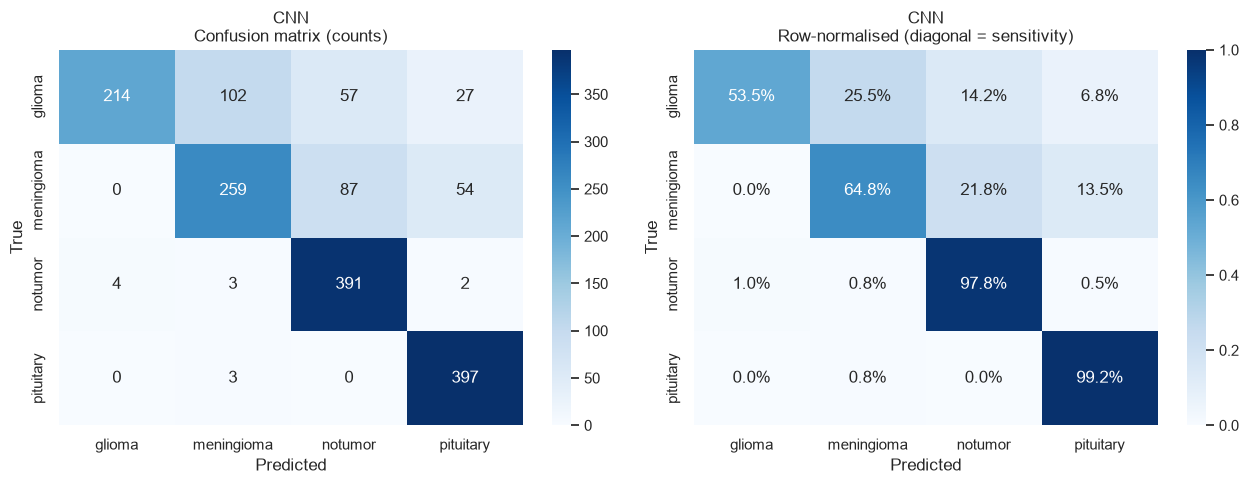

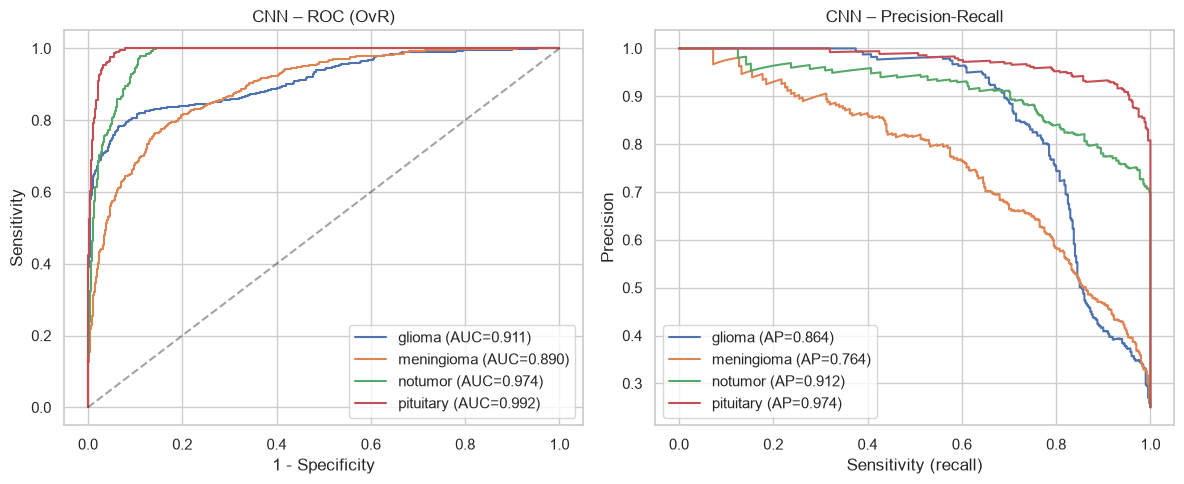

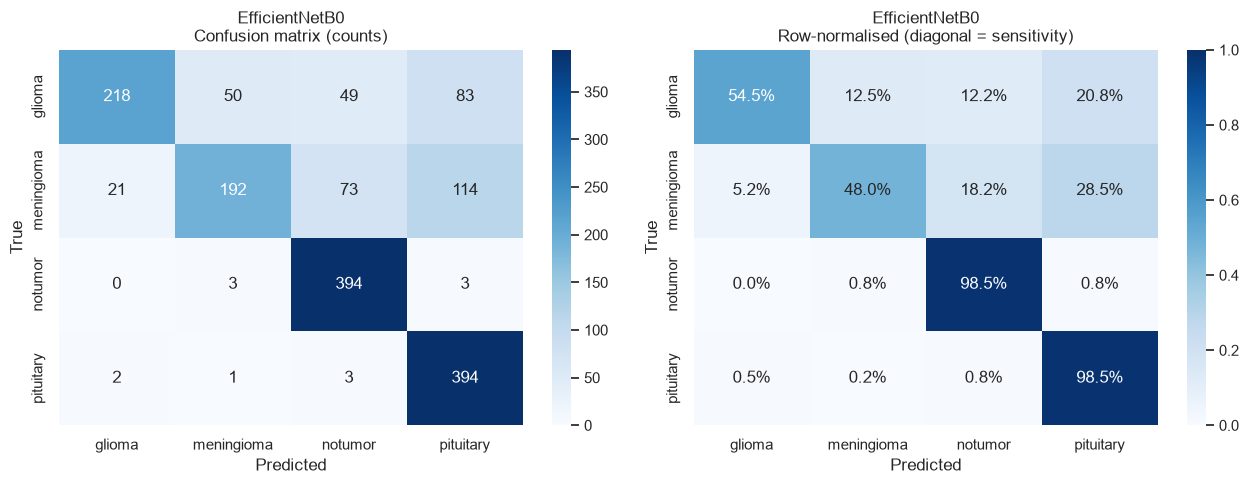

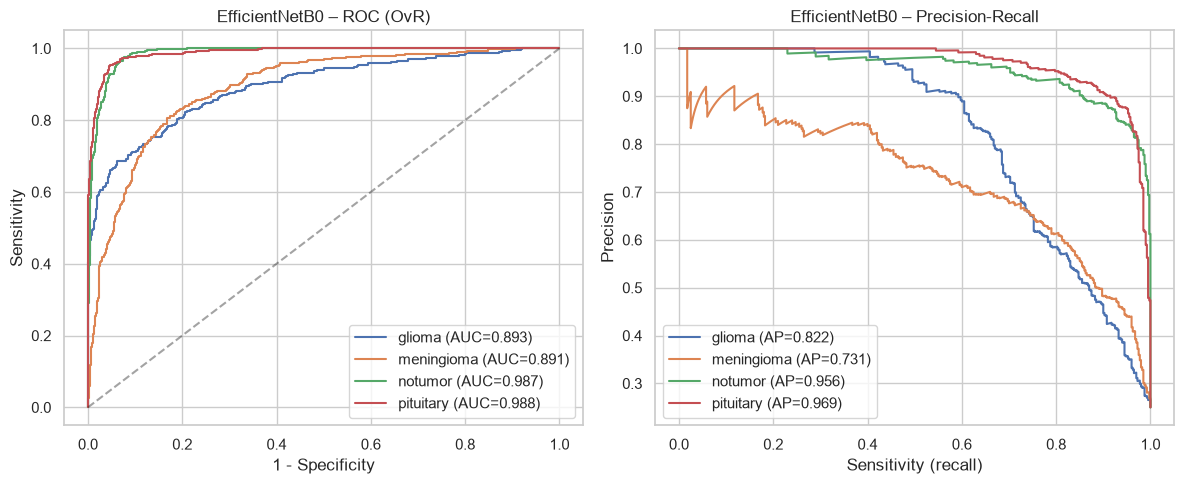

In [10]:
for name, r in registry.items():
    yt, pt, probt = r["test"]
    plot_confusion_matrices(cms[name], class_names, name, f"cm_{name}")
    plot_roc_pr(yt, probt, class_names, name, f"roc_pr_{name}")

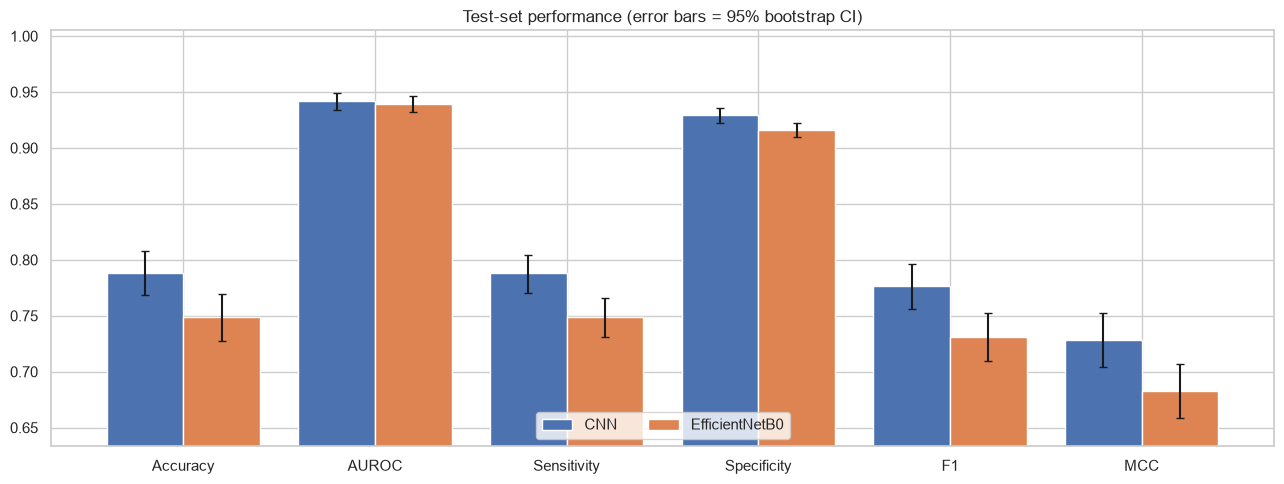

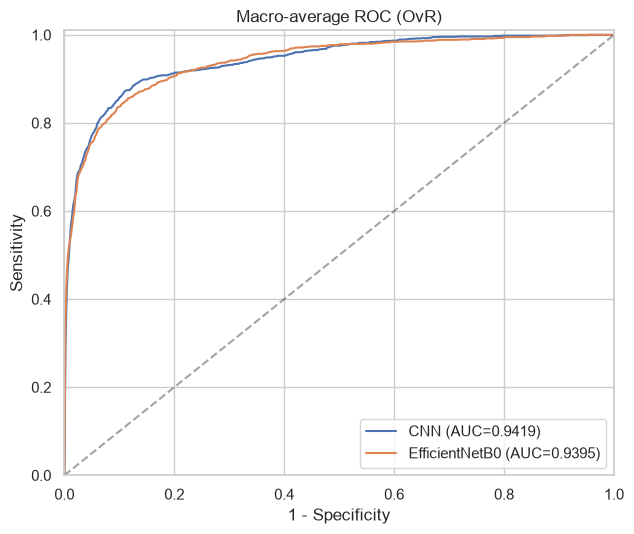

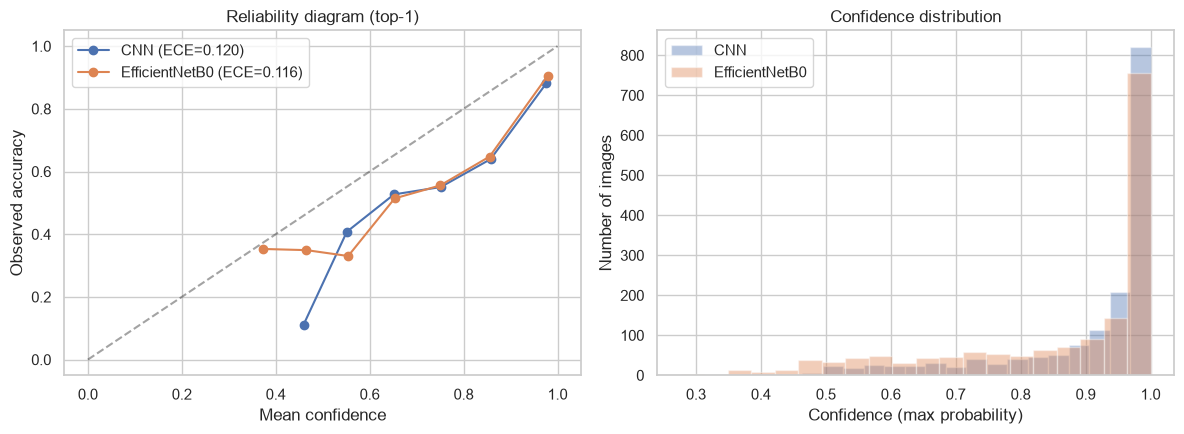

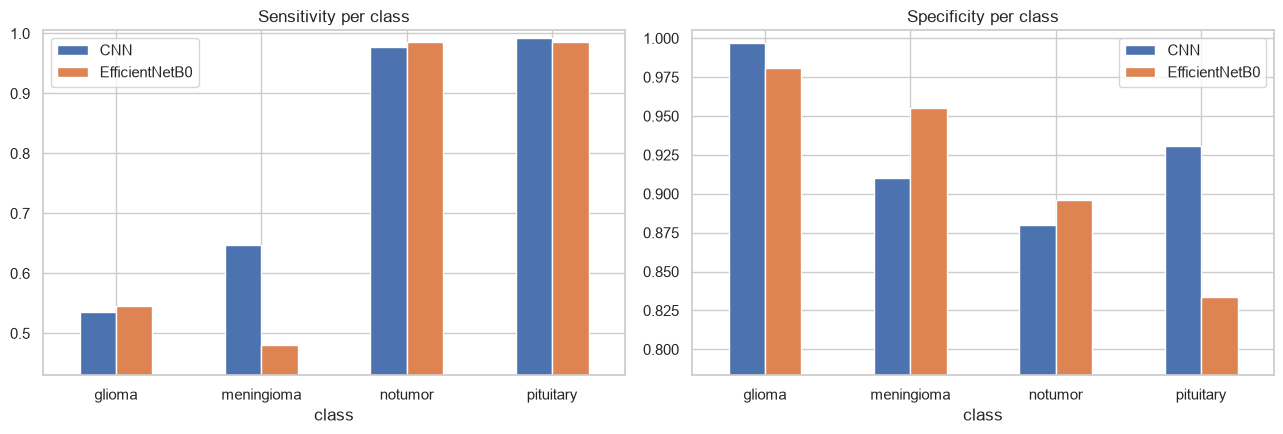

In [12]:
# (a) Metric comparison with 95% CIs
mets = ["accuracy", "auroc_macro", "sens_macro", "spec_macro", "f1_macro", "mcc"]
labels = ["Accuracy", "AUROC", "Sensitivity", "Specificity", "F1", "MCC"]
fig, ax = plt.subplots(figsize=(13, 5)); w = 0.8 / len(registry)
for k, (name, r) in enumerate(registry.items()):
    vals = np.array([r["gm"][m] for m in mets]); lo, hi = r["ci"]
    err = np.vstack([vals - lo[mets].values, hi[mets].values - vals])
    ax.bar(np.arange(len(mets)) + k * w, vals, w, yerr=err, capsize=3, label=name)
ax.set_xticks(np.arange(len(mets)) + w * (len(registry) - 1) / 2); ax.set_xticklabels(labels)
ax.set_ylim(max(0, min(summary[mets].min()) - 0.05), 1.005); ax.legend(ncol=len(registry), loc="lower center")
ax.set_title("Test-set performance (error bars = 95% bootstrap CI)")
plt.tight_layout(); savefig("metric_comparison"); plt.show()

# (b) Macro-average ROC of all models
plt.figure(figsize=(6.5, 5.5))
for name, r in registry.items():
    g, m = macro_roc(r["test"][0], r["test"][2], K)
    plt.plot(g, m, label=f"{name} (AUC={r['gm']['auroc_macro']:.4f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.4); plt.xlim(0, 1); plt.ylim(0, 1.01)
plt.xlabel("1 - Specificity"); plt.ylabel("Sensitivity"); plt.title("Macro-average ROC (OvR)")
plt.legend(loc="lower right"); plt.tight_layout(); savefig("roc_macro_all"); plt.show()

# (c) Calibration curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
edges = np.linspace(0, 1, 11)
for name, r in registry.items():
    yt, pt, probt = r["test"]; conf = probt.max(1); acc = (pt == yt).astype(float)
    xs, ys = [], []
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        m = (conf > lo_) & (conf <= hi_)
        if m.sum() >= 5: xs.append(conf[m].mean()); ys.append(acc[m].mean())
    ax[0].plot(xs, ys, marker="o", label=f"{name} (ECE={r['gm']['ece']:.3f})")
    ax[1].hist(conf, bins=20, alpha=.4, label=name)
ax[0].plot([0, 1], [0, 1], "k--", alpha=.4)
ax[0].set(xlabel="Mean confidence", ylabel="Observed accuracy", title="Reliability diagram (top-1)"); ax[0].legend()
ax[1].set(xlabel="Confidence (max probability)", ylabel="Number of images", title="Confidence distribution"); ax[1].legend()
plt.tight_layout(); savefig("calibration"); plt.show()

# (d) Sensitivity and specificity per class
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, col, t in zip(ax, ["sensitivity", "specificity"], ["Sensitivity per class", "Specificity per class"]):
    tab = pd.DataFrame({n: per_class[n][col] for n in registry})
    tab.plot(kind="bar", ax=a, rot=0); a.set_title(t); a.set_ylim(max(0, tab.min().min() - 0.05), 1.005)
plt.tight_layout(); savefig("sens_spec_per_class"); plt.show()

## 10. Paired statistical comparison (exact McNemar, Bonferroni correction)

McNemar compares two models on the **same** test images, using only the cases where exactly one of them is right. With a single model (`RUN_MODELS` of length 1) this section simply produces an empty table.

,A,B,A_right_B_wrong,A_wrong_B_right,p_raw,p_bonferroni
0,CNN,EfficientNetB0,128,65,0.0,0.0


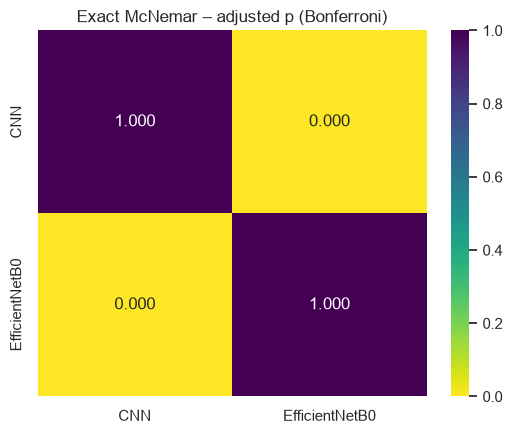

In [13]:
names = list(registry); yt = registry[names[0]]["test"][0]
n_comp = max(1, len(names) * (len(names) - 1) // 2)
P = pd.DataFrame(np.ones((len(names), len(names))), index=names, columns=names)
detail = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        p, b, c = mcnemar_exact(yt, registry[names[i]]["test"][1], registry[names[j]]["test"][1])
        P.iloc[i, j] = P.iloc[j, i] = min(1.0, p * n_comp)
        detail.append({"A": names[i], "B": names[j], "A_right_B_wrong": b, "A_wrong_B_right": c,
                       "p_raw": p, "p_bonferroni": min(1.0, p * n_comp)})
display(pd.DataFrame(detail).round(4))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(P, annot=True, fmt=".3f", cmap="viridis_r", vmin=0, vmax=1)
plt.title("Exact McNemar – adjusted p (Bonferroni)"); plt.tight_layout(); savefig("mcnemar"); plt.show()

## 11. Error analysis and Grad-CAM (best model by validation)

Lists which class pairs are confused most often and overlays Grad-CAM heat maps on the most confident correct and incorrect predictions. Grad-CAM is a qualitative sanity check (is the model looking at the brain or at artefacts/borders?), not proof that it uses the tumour.

Best model: CNN | test errors: 339 of 1600


,true,predicted,n
0,glioma,meningioma,102
1,meningioma,notumor,87
2,glioma,notumor,57
3,meningioma,pituitary,54
4,glioma,pituitary,27
5,notumor,glioma,4
6,notumor,meningioma,3
7,pituitary,meningioma,3
8,notumor,pituitary,2


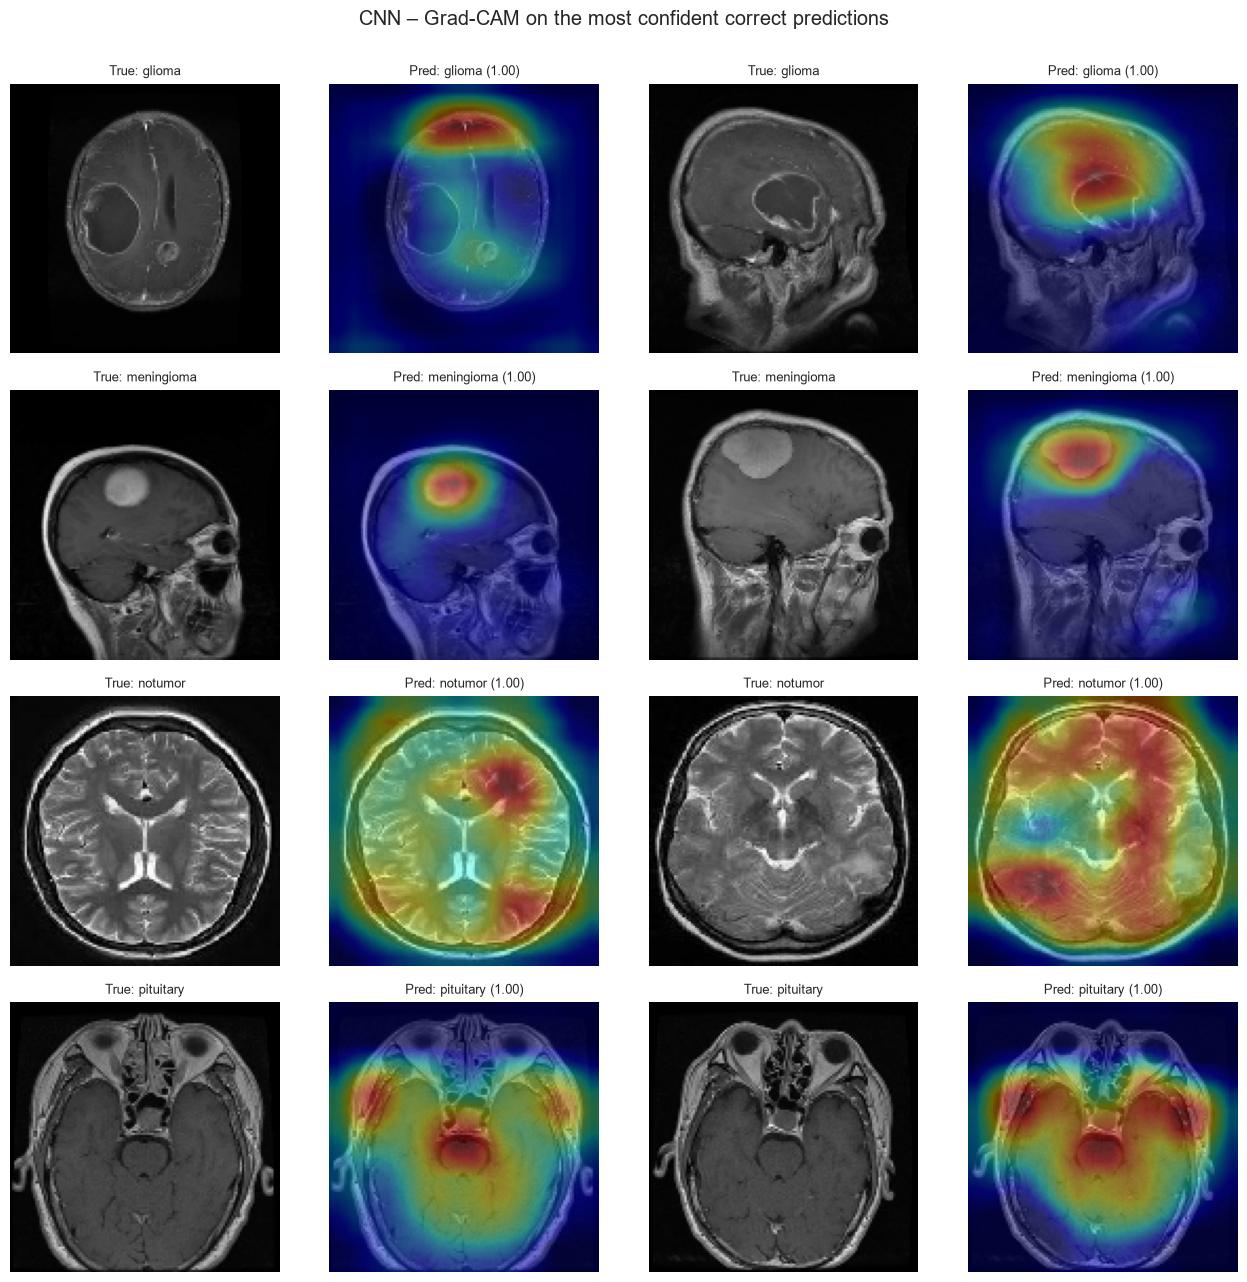

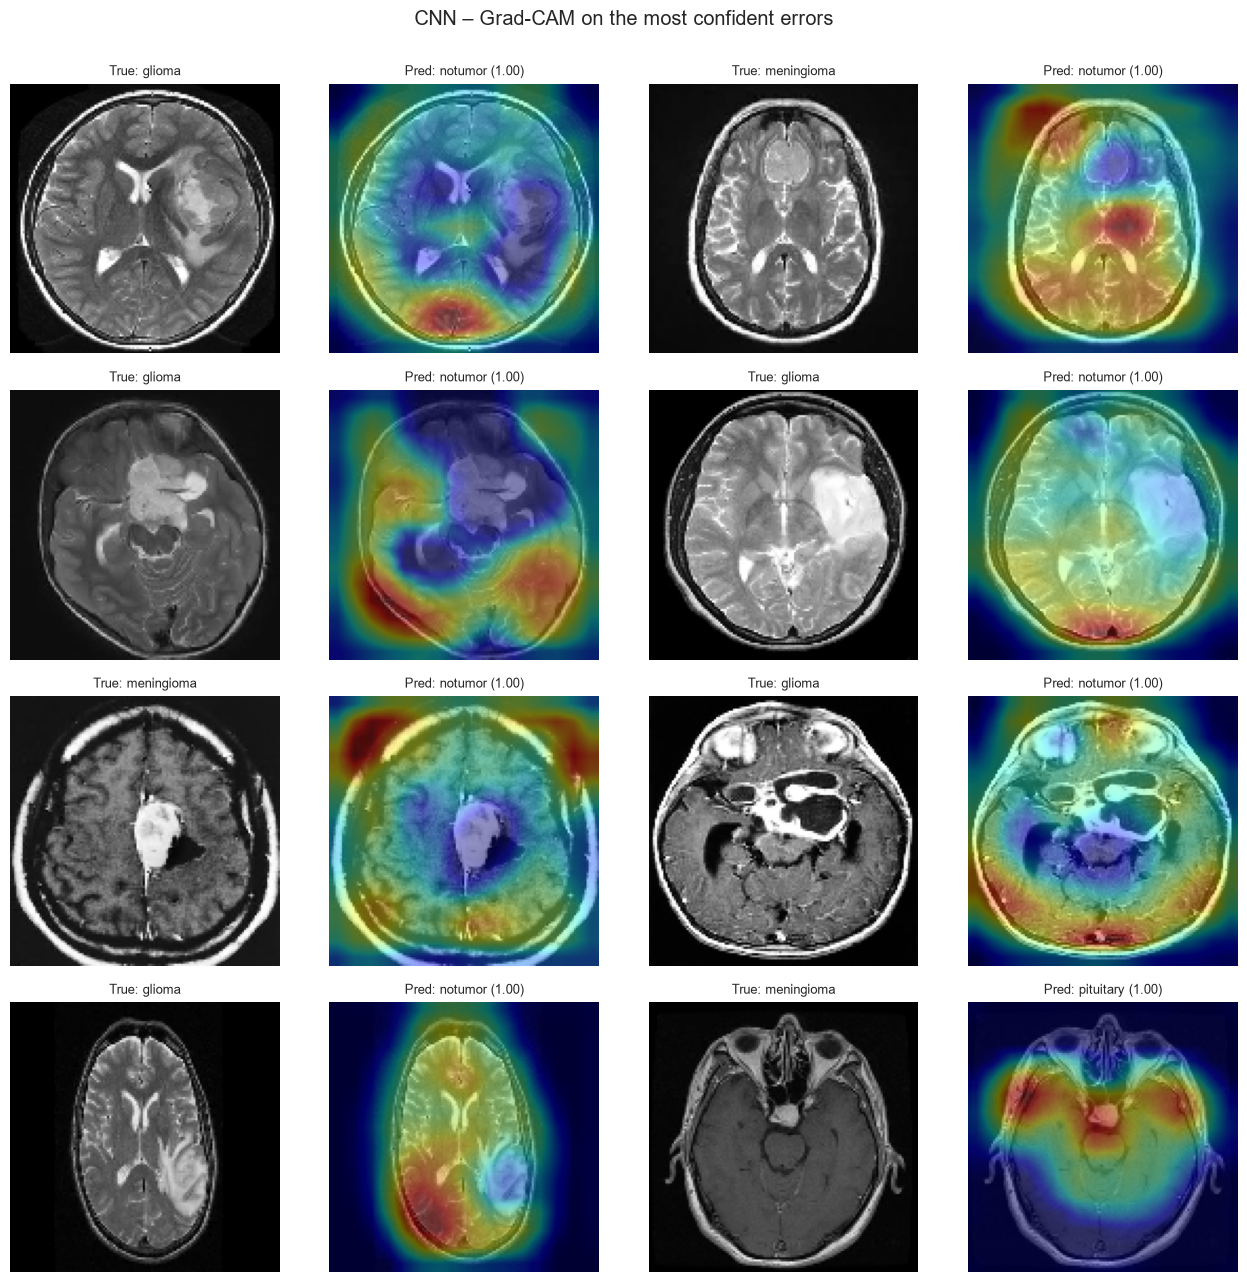

In [14]:
def compute_cam(name, img_batch, class_idx=None):
    r = registry[name]; model, base = r["model"], r["base"]
    x = tf.convert_to_tensor(img_batch, tf.float32)
    if name == "CNN":
        gm = keras.Model(model.inputs, [model.get_layer(f"blk{len(FILTERS) - 1}_act2").output, model.output])
        with tf.GradientTape() as tape:
            fmap, preds = gm(x, training=False)
            if class_idx is None: class_idx = int(tf.argmax(preds[0]))
            score = preds[:, class_idx]
    else:
        if any(l.name == "prep" for l in model.layers): x = model.get_layer("prep")(x)
        with tf.GradientTape() as tape:
            fmap = base(x, training=False)
            tape.watch(fmap)
            h = model.get_layer("gap")(fmap)
            h = model.get_layer("drop")(h, training=False)
            preds = model.get_layer("out")(h)
            if class_idx is None: class_idx = int(tf.argmax(preds[0]))
            score = preds[:, class_idx]
    grads = tape.gradient(score, fmap)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * fmap, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), preds[0].numpy(), class_idx

def show_gradcam(name, samples, title, fname):
    n = len(samples); rows = int(np.ceil(n / 2))
    fig, axes = plt.subplots(rows, 4, figsize=(13, 3.2 * rows)); axes = np.atleast_2d(axes)
    for a in axes.ravel(): a.axis("off")
    for k, (_, s) in enumerate(samples.iterrows()):
        img = np.asarray(keras.utils.load_img(s["path"], target_size=IMG_SIZE), dtype="float32")
        cam, probs, cidx = compute_cam(name, img[None])
        cam_r = tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]
        a1, a2 = axes[k // 2, (k % 2) * 2], axes[k // 2, (k % 2) * 2 + 1]
        a1.imshow(img.astype("uint8")); a2.imshow(img.astype("uint8")); a2.imshow(cam_r, cmap="jet", alpha=.4)
        a1.set_title(f"True: {class_names[s['label']]}", fontsize=9)
        a2.set_title(f"Pred: {class_names[cidx]} ({probs[cidx]:.2f})", fontsize=9)
    fig.suptitle(title, y=1.0); plt.tight_layout(); savefig(fname); plt.show()

yt, pt, probt = registry[best]["test"]
pred_df = test_df.copy(); pred_df["pred"] = pt; pred_df["conf"] = probt.max(1)
pred_df["ok"] = pred_df["pred"] == pred_df["label"]
print(f"Best model: {best} | test errors: {(~pred_df.ok).sum()} of {len(pred_df)}")

idx2name = dict(enumerate(class_names))
conf_pairs = (pred_df[~pred_df.ok].assign(true=lambda d: d["label"].map(idx2name),
                                           predicted=lambda d: d["pred"].map(idx2name))
              .groupby(["true", "predicted"]).size().sort_values(ascending=False).rename("n").reset_index())
display(conf_pairs)

right = pd.concat([pred_df[(pred_df.label == c) & pred_df.ok].nlargest(2, "conf") for c in range(K)])
wrong = pred_df[~pred_df.ok].nlargest(8, "conf")
show_gradcam(best, right, f"{best} – Grad-CAM on the most confident correct predictions", "gradcam_correct")
if len(wrong): show_gradcam(best, wrong, f"{best} – Grad-CAM on the most confident errors", "gradcam_errors")

## 12. Efficiency and export

Everything needed for a report or paper is written to `outputs/`: CSV/Excel tables, 300-dpi figures in `outputs/figures/`, model weights in `outputs/weights/`, and per-image test predictions (to re-run any metric later without retraining).

In [16]:
eff = pd.DataFrame({n: {"total_parameters": r["model"].count_params(),
                        "train_time_min": r["train_time_s"] / 60,
                        "inference_ms_per_image": r["ms_per_image"],
                        "validation_mcc": r["val_mcc"]} for n, r in registry.items()}).T
display(eff.round(3))

summary_ci.to_csv(OUT / "global_metrics_CI95.csv")
summary.round(5).to_csv(OUT / "global_metrics_point.csv")
eff.round(4).to_csv(OUT / "efficiency.csv")
pd.concat(per_class, names=["model"]).round(5).to_csv(OUT / "per_class_metrics.csv")
pd.DataFrame(detail).to_csv(OUT / "mcnemar.csv", index=False)
for n, cm in cms.items():
    pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(OUT / f"confusion_matrix_{n}.csv")
    yt_, pt_, pr_ = registry[n]["test"]
    out = test_df[["path", "class"]].copy(); out["pred"] = [class_names[i] for i in pt_]
    for i, c in enumerate(class_names): out[f"p_{c}"] = pr_[:, i]
    out.to_csv(OUT / f"test_predictions_{n}.csv", index=False)

try:
    with pd.ExcelWriter(OUT / "results.xlsx") as xw:
        summary_ci.to_excel(xw, sheet_name="global_CI95"); summary.round(5).to_excel(xw, sheet_name="global_point")
        pd.concat(per_class, names=["model"]).round(5).to_excel(xw, sheet_name="per_class")
        eff.round(4).to_excel(xw, sheet_name="efficiency"); pd.DataFrame(detail).to_excel(xw, sheet_name="mcnemar", index=False)
        for n, cm in cms.items():
            pd.DataFrame(cm, index=class_names, columns=class_names).to_excel(xw, sheet_name=f"cm_{n}"[:31])
except Exception as e:
    print("Excel file not created:", e)

print("Files saved in:", OUT.resolve())
print(sorted(p.name for p in OUT.iterdir()))

,total_parameters,train_time_min,inference_ms_per_image,validation_mcc
CNN,311988.0,31.016,5.580,0.882
EfficientNetB0,4054695.0,15.345,9.003,0.760


Files saved in: C:\Users\sanch\outputs
['confusion_matrix_CNN.csv', 'confusion_matrix_EfficientNetB0.csv', 'efficiency.csv', 'environment.json', 'figures', 'global_metrics_CI95.csv', 'global_metrics_point.csv', 'image_inventory.csv', 'inventario_imagens.csv', 'mcnemar.csv', 'per_class_metrics.csv', 'results.xlsx', 'test_predictions_CNN.csv', 'test_predictions_EfficientNetB0.csv', 'weights']


## Methodological notes

- **Sensitivity / specificity:** computed per class (*one-vs-rest*) from the confusion matrix and then macro-averaged. Per-class CIs use the **Wilson** method; global CIs use a **bootstrap** (2.5–97.5 percentiles) over test images.
- **AUROC:** macro one-vs-rest (also per class, with ROC and precision-recall curves).
- **MCC:** multiclass (Gorodkin, `sklearn`) as the global measure; `MCC_ovr` per class.
- **Calibration:** multiclass Brier score and ECE (15 bins); the reliability diagram shows whether the probabilities can be trusted.
- **Model comparison:** exact McNemar on paired predictions, Bonferroni-corrected.
- **Leakage:** report results with and without removing duplicates/near-duplicates. Slices from the same patient may still fall in different splits (no patient ID available).
- **Grad-CAM:** a qualitative inspection tool; it does not prove the model relies on the tumour region.
- **External validation:** for real generalisation, test on another dataset/institution. To estimate training variability, repeat with several seeds or use stratified cross-validation.
- **Reporting checklist:** for imaging-AI papers, consider following CLAIM.
- **Not a medical device:** this is a research/teaching pipeline; the models must not be used for clinical decisions.